In [2]:

import numpy as np
import pandas as pd
import os
import rioxarray as rxr
from osgeo import gdal
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline, make_pipeline
import geopandas as gpd
import rasterio
from shapely.geometry import box
from shapely.geometry import Point
from rasterio.sample import sample_gen
import xgboost as xgb

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Real
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.family'] = 'Arial'

c:\Users\minyu\.conda\envs\ICESAT_env\lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


In [3]:
def save_img(output_filename, reference_filename, array):
    # 打开参考数据
    reference = gdal.Open(reference_filename)
    
    # 获取地理变换参数和坐标系
    geo_transform = reference.GetGeoTransform()
    projection = reference.GetProjection()

    # 获取矩阵尺寸
    rows, cols = array.shape

    # 创建新的 TIFF 数据集
    driver = gdal.GetDriverByName('GTiff')
    out_data = driver.Create(output_filename, cols, rows, 1, gdal.GDT_Float32)

    # 设置地理变换和坐标系
    out_data.SetGeoTransform(geo_transform)
    out_data.SetProjection(projection)
    

    # 写入数据
    out_data.GetRasterBand(1).WriteArray(array)

    # 保存并关闭文件
    out_data.FlushCache()
    out_data = None
    
def optimize_random_forest(x_train, y_train,  n_iter=30, cv=3):

    # if feature_columns is None:
    #     raise ValueError("feature_columns must be provided.")

    classifier = RandomForestRegressor(random_state=42)

    search_space = {
        'n_estimators': Integer(50, 500),
        'max_depth': Integer(3, 20),
        'min_samples_split': Integer(2, 20),
        'min_samples_leaf': Integer(1, 20),
        'max_features': Real(0.1, 1.0)
    }

    opt = BayesSearchCV(
        estimator=classifier,
        search_spaces=search_space,
        n_iter=n_iter,
        cv=cv,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )

    opt.fit(x_train, y_train)

    best_params = opt.best_params_
    print('Best hyperparameters:', best_params)
    print('Best score (negative MSE):', opt.best_score_)

    # 使用最优参数重新训练模型
    final_model = RandomForestRegressor(**best_params, random_state=42)
    # final_model.fit(x_train, y_train)

    return best_params, final_model

In [ ]:
path = 'G:\ICESat-2\Discussion5_2_new\Thames_random_points.shp'
data = gpd.read_file(path)
data.columns 

Index(['FID_1', 'Refer', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'geometry'],
      dtype='object')

In [13]:
#-----------------------------discuss 5.1 Multii-metrics VS Frequency-only------------------------------

# simply output result
# region = 'Morecambe'
location = 'Thames'
Feature_band = 4
drop_rate = 0
year = 2019

ICESAT_point_path = f"G:\ICESat-2\Discussion5_2_new\A_{location}2_30m_{year}_new10.shp"
# ICESAT_point_path = f'G:\ICESat-2\Discussion5_2_new\{location}_random_points.shp'
FB_raster_path = f'G:\ICESat-2\Discussion5_2_new\{location}1_{year}_FB6_new9.tif'
output_path =  f'G:\ICESat-2\Discussion5_2_new\{location}2_{year}_RF_FB6_bys_SY.tif'

target_band = ['b1_FB6',  'b2_FB6','b3_FB6', 'b4_FB6']
target_id = [0, 1, 2, 3]

data = gpd.read_file(ICESAT_point_path)


y_train = data['OH'].values
x_train = data[target_band[:Feature_band]].values
print('x_train:', x_train.shape, '\n', 'y_train', y_train.shape)

# RF fit
best_params, classifier = optimize_random_forest(x_train, y_train)
classifier.fit(x_train, y_train)
# Topograph mapping 

raster = rxr.open_rasterio(FB_raster_path).values
raster = np.nan_to_num(raster, nan = 0)
selected_raster = raster[target_id[:Feature_band], :, :]

if len(selected_raster.shape) != 3:
    row, col = selected_raster.shape
    selected_raster = selected_raster.reshape(1, row, col)
else: 
    bands, row, col = selected_raster.shape

print('selected_raster.shape', selected_raster.shape)

k = 0
result = np.array([[]])
for i in range(row):
    
    x_train = np.transpose(selected_raster[:, i, :])
    y_pred = classifier.predict(x_train)
    
    result = np.append(result, y_pred)
    
    if i%(int(row/5)) == 0:
        
        print(k*20 , '%_ is done')
        k = k+1
        
result_ =  result.reshape(row, col)
print(result.shape, type(result))
tf_mask = raster[6,:,:]

result_[tf_mask == 0] = 0

save_img(output_path, FB_raster_path, result_)
print('File output to :', output_path)
#-------------------------------------------------------------------------------------------

x_train: (2677, 4) 
 y_train (2677,)
Best hyperparameters: OrderedDict([('max_depth', 17), ('max_features', 0.4942262677968311), ('min_samples_leaf', 11), ('min_samples_split', 15), ('n_estimators', 457)])
Best score (negative MSE): -0.15499710503083597
selected_raster.shape (4, 1728, 1575)
0 %_ is done
20 %_ is done
40 %_ is done
60 %_ is done
80 %_ is done
100 %_ is done
(2721600,) <class 'numpy.ndarray'>
File output to : G:\ICESat-2\Discussion5_2_new\Thames2_2019_RF_FB6_bys_SY.tif


In [52]:
import rasterio
import numpy as np
import geopandas as gpd
from shapely.geometry import Point

# 输入与输出
tif_path = "G:\ICESat-2\Discussion5_2_new\wash_bay_2022_FB6_new9.tif"
n_points = 3150  # 想要生成的点数量
output_shp = "G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp"

# 打开影像
with rasterio.open(tif_path) as src:
    data = src.read(7)  # 读取第一波段
    transform = src.transform

    # 创建 mask：只在 value <= 6 的区域取样
    valid_mask = (data == 1 ) & (~np.isnan(data))
    valid_indices = np.argwhere(valid_mask)

    if len(valid_indices) < n_points:
        raise ValueError("有效像元不足，无法生成这么多点！")

    # 随机选择像元位置
    chosen_idx = valid_indices[np.random.choice(len(valid_indices), n_points, replace=False)]

    # 转换为地理坐标
    points = []
    for row, col in chosen_idx:
        x, y = rasterio.transform.xy(transform, row, col)
        points.append(Point(x, y))

# 存储为 shapefile
gdf = gpd.GeoDataFrame(geometry=points, crs=src.crs)
gdf.to_file(output_shp)

print(f"✅ 已生成 {n_points} 个随机点，保存到 {output_shp}")


✅ 已生成 3150 个随机点，保存到 G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp


In [3]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
from rasterio.transform import from_origin
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.geometry import box
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from scipy.stats import pearsonr
from sklearn.metrics import r2_score
import pandas as pd
import numpy as np
import rioxarray as rxr

In [ ]:
#-------------------------------for Retrieval DTM validation----------------------------

region = 'Region3'
location = 'Thames'
location2 = 'Thames'
method = 'RF'
Bands = 4
year_num = 'bys'
year_list = [2019]

for i in range(len(year_list)):
    
    year = year_list[i]
    ref_dem_path = f"G:\DTM_ref\{location2}\{location2}_{year}\{location2}_masked_{year}.tif"
    # ref_dem_path = 'G:\DTM_ref\Carmarthen\Carmarthen_2021\Carmarthen_masked_2021.tif'
    #retrieved_dem_path = f"G:\ICESat-2\{region}_map\{location}_map\A{year}\{location}_{year}_{Bands}_{method}_FB6_new10_AAA.tif"
    retrieved_dem_path = f"G:\ICESat-2\Discussion5_2_new\Thames_2019_random_RF_FB6.tif"
    # retrieved_dem_path = f"G:\ICESat-2\Discussion5_2_new\Thames_2019_ICESat_RF_FB6.tif"
    validation_sample_path = f'G:\ICESat-2\Discussion5_2_new\{location}_{year}_validation_points.shp'
    # validation_sample_csv_path = f'G:\ICESat-2\{region}_map\{location}_map\A{year}/{location}_{year}_sample_points.csv'

    with rasterio.open(ref_dem_path) as src1, rasterio.open(retrieved_dem_path) as src2:
        # 计算交集区域（bounding box）
        bounds1 = src1.bounds
        bounds2 = src2.bounds

        intersection = box(
            max(bounds1.left, bounds2.left),
            max(bounds1.bottom, bounds2.bottom),
            min(bounds1.right, bounds2.right),
            min(bounds1.top, bounds2.top)
        )

        if intersection.is_empty:
            raise ValueError("两个 raster 没有空间交集")

        # 统一坐标系（假设两个 raster 已经在同一坐标系，否则需要 reproject）

        # 设置目标分辨率与 shape
        res = 30
        width = int((intersection.bounds[2] - intersection.bounds[0]) / res)
        height = int((intersection.bounds[3] - intersection.bounds[1]) / res)
        transform = from_origin(intersection.bounds[0], intersection.bounds[3], res, res)

        # 重采样并裁剪两个 raster 到相同区域和分辨率
        def reproject_to_common(src):
            dst_array = np.empty((height, width), dtype=src.read(1).dtype)
            reproject(
                source=rasterio.band(src, 1),
                destination=dst_array,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs=src.crs,
                resampling=Resampling.nearest
            )
            return dst_array

        data1 = reproject_to_common(src1)
        data2 = reproject_to_common(src2)
        crs = src1.crs

    # 创建有效掩膜
    mask1 = (data1 != src1.nodata) & (data1 != 6) & (data1 != 0)
    mask2 = (data2 != src2.nodata) & (data2 != 0)
    valid_mask = mask1 & mask2

    valid_indices = np.argwhere(valid_mask)

    if len(valid_indices) == 0:
        raise ValueError("没有满足条件的像元")

    # 随机抽样点
    n_points = int(len(valid_indices)/30)
    sampled_indices = valid_indices[np.random.choice(len(valid_indices), n_points, replace=False)]

    points = []
    vals1 = []
    vals2 = []

    for row, col in sampled_indices:
        x, y = transform * (col + 0.5, row + 0.5)
        points.append(Point(x, y))
        vals1.append(data1[row, col])
        vals2.append(data2[row, col])

    gdf = gpd.GeoDataFrame({
        'Refer_dem': vals1,
        'retrieved_dem': vals2
    }, geometry=points, crs=crs)

    # 保存结果
    gdf.to_file(validation_sample_path)
    
    z = gdf.dropna()

    x = z['Refer_dem']
    y = z['retrieved_dem']
    y = np.array(y)
    x = np.array(x)

    # 以 x 为真实值，y 为预测值进行评价
    R = r2_score(x, y)  # R²
    MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
    MSB = np.mean(x - y)          # Mean Signed Bias
    RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
    num = len(x)
        

    xy = np.vstack([x,y])  #  将两个维度的数据叠加
    z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
    idx = z.argsort()
    x, y, z = x[idx], y[idx], z[idx]

    fig, ax = plt.subplots()
    textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
    name = f'{location2} ({year})'
    ax.text(0.05, 0.95, textstr, transform = ax.transAxes, fontsize = 16, verticalalignment = 'top')
    ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

    ax.set_xlabel('Reference dem', fontsize = 15)
    ax.set_ylabel('ICESat-2 dem', fontsize = 15)
    ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
    sc = plt.scatter(x, y, c=z, s=5, cmap='Spectral_r', zorder=2)
    cbar = plt.colorbar(sc)

    ax.set_xlim(-3, 4)
    ax.set_ylim(-3, 4)
    ax.tick_params(axis='both', labelsize=12)

In [3]:
validation_sample_path = f'G:\ICESat-2\Discussion5_2_new\Thames1_2019_sample_points_final.shp'
validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\Ribble1_2022_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\wash_bay_2022_sample_points_final.shp'
gdf = gpd.read_file(validation_sample_path)
z = gdf.dropna()
z.columns

Index(['Refer_dem', 'retrieved_', 'SY', 'DEM_new9', 'DEM_ICESat', 'DEM_random',
       'ICE_SY', 'DEM98', 'geometry'],
      dtype='object')

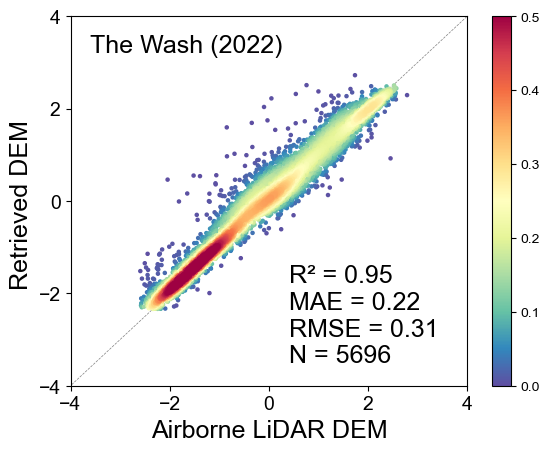

In [24]:
# validation_sample_path = f'G:\ICESat-2\Discussion5_2_new\Thames1_2019_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\Thames1_2019_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_1_new\Ribble1_2022_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\Morecambe_2023_sample_points_final.shp'
validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\wash_bay_2022_sample_points_final.shp'
output_path =  'G:\ICESat-2\Discussion5_2_new\plot\Wash_ICESat_plot.png'
gdf = gpd.read_file(validation_sample_path)
z = gdf.dropna()

z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()

# z = gdf.dropna()
# mask = z['DEM_new9'] != 0
# z = z[mask]
# z = z[z['Refer_dem']!=0]
# z = z[z['Refer_dem']!=6]


x = z['Refer_dem']
y = z['ICE_SY']
# y = z['DEM_random']
y = np.array(y)
x = np.array(x)

    # 以 x 为真实值，y 为预测值进行评价
R = r2_score(x, y)  # R²
MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
MSB = np.mean(x - y)          # Mean Signed Bias
RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
num = len(x)
# num = 5739

xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
textstr2 = f"(0.95)\n    (0.22)\n       (0.31)\n"
name = f'The Wash (2022)'
ax.text(0.05, 0.95, name, transform = ax.transAxes, fontsize = 18, verticalalignment = 'top')

ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=18, verticalalignment='bottom', horizontalalignment='left')
# ax.text(0.43, 0.05, textstr, transform=ax.transAxes, fontsize=18, verticalalignment='bottom', horizontalalignment='left')
# ax.text(0.70, 0.05, textstr2, transform = ax.transAxes, fontsize = 18, verticalalignment = 'bottom', horizontalalignment='left', color = 'red')
# ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Airborne LiDAR DEM', fontsize = 18)
ax.set_ylabel('Retrieved DEM ', fontsize = 18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.5, zorder=1)
sc = plt.scatter(x, y, c=z, s=5, vmin=0, vmax= 0.5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

ax.set_xlim(-4, 4)
ax.set_ylim(-4, 4)
ax.set_yticks(np.arange(-4, 4.1, 2))
ax.set_xticks(np.arange(-4, 4.1, 2))
ax.tick_params(axis='both', labelsize=14)
# plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像

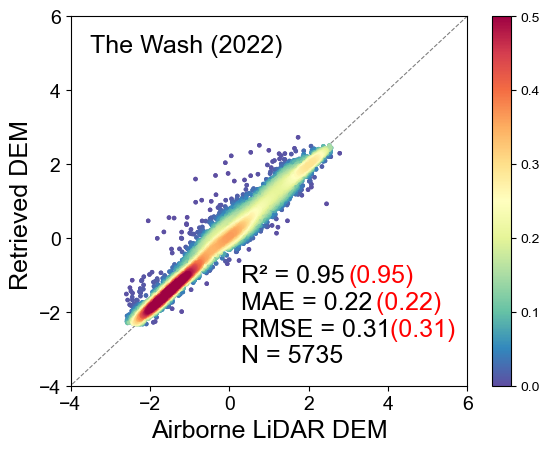

In [27]:
# validation_sample_path = f'G:\ICESat-2\Discussion5_2_new\Thames1_2019_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\Ribble1_2022_sample_points_final.shp'
# validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\Morecambe_2023_sample_points_final.shp'
validation_sample_path = 'G:\ICESat-2\Discussion5_2_new\wash_bay_2022_sample_points_final.shp'
output_path =  'G:\ICESat-2\Discussion5_2_new\plot\Wash_ICESat_plot.png'
gdf = gpd.read_file(validation_sample_path)
z = gdf.dropna()

z = z[z!=-999]
z = z[z!=6]
z = z[z!=0]
z = z.dropna()

x = z['Refer_dem']
y = z['DEM_ICESat']
# y = z['DEM_random']
y = np.array(y)
x = np.array(x)

    # 以 x 为真实值，y 为预测值进行评价
R = r2_score(x, y)  # R²
MAD = np.mean(np.abs(x - y))  # Mean Absolute Deviation
MSB = np.mean(x - y)          # Mean Signed Bias
RMSE = np.sqrt(np.mean((x - y)**2))  # Root Mean Squared Error
num = len(x)
num = 5735
        

xy = np.vstack([x,y])  #  将两个维度的数据叠加
z = gaussian_kde(xy)(xy)  # 建立概率密度分布，并计算每个样本点的概率密度

    # Sort the points by density, so that the densest points are plotted last
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R:.2f}\nMAE = {MAD:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"
textstr2 = f"(0.95)\n    (0.22)\n      (0.31)\n"
name = f'The Wash (2022)'
ax.text(0.05, 0.95, name, transform = ax.transAxes, fontsize = 18, verticalalignment = 'top')

# ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=18, verticalalignment='bottom', horizontalalignment='left')
ax.text(0.43, 0.05, textstr, transform=ax.transAxes, fontsize=18, verticalalignment='bottom', horizontalalignment='left')
ax.text(0.70, 0.05, textstr2, transform = ax.transAxes, fontsize = 18, verticalalignment = 'bottom', horizontalalignment='left', color = 'red')
# ax.text(0.95, 0.05, name, transform=ax.transAxes, fontsize=16, verticalalignment='bottom', horizontalalignment='right')

ax.set_xlabel('Airborne LiDAR DEM', fontsize = 18)
ax.set_ylabel('Retrieved DEM ', fontsize = 18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)
sc = plt.scatter(x, y, c=z, s=5, vmin=0, vmax= 1, cmap='Spectral_r', zorder=2)
# cbar = plt.colorbar(sc, orientation='horizontal')
# cbar.set_label("Density", fontsize=14)       # 设置横向颜色条标题的字体大小
# cbar.ax.tick_params(labelsize=14)   

sc = plt.scatter(x, y, c=z, s=5, vmin=0, vmax= 0.5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)

ax.set_xlim(-4, 6)
ax.set_ylim(-4, 6)
ax.set_yticks(np.arange(-4, 6.1, 2))
ax.set_xticks(np.arange(-4, 6.1, 2))
ax.tick_params(axis='both', labelsize=14)
plt.savefig(output_path, dpi=300, bbox_inches='tight')  # 保存图像

In [22]:
path_ = 'G:\ICESat-2\Region1_map\Thames_map\A2019\A_Thames_30m_2019_new10_valid_kk.shp'
a = gpd.read_file(path_)
a.columns

Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'Ref_dem', 'Re_dem', 'dif', 'geometry'],
      dtype='object')

Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'geometry'],
      dtype='object')
Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'geometry'],
      dtype='object')


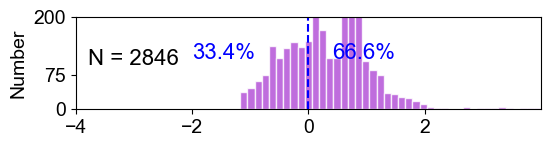

In [23]:
path_ = 'G:\ICESat-2\Region1_map\Thames1_map\A2019\A_Thames1_30m_2019_new10.shp'
data = gpd.read_file(path_)
print(data.columns)
data = data[(data['OH'] != -999)&(data['OH'] != 6)]
print(data.columns)
drop_rate = 0
# data = gpd.read_file(path_)
# data.columns
data = data.sort_values(by = 'OH')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['OH']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 1.2))
plt.text(-3.8, 130, f"N = {len(Z_half)}", fontsize=16, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#B048D5FF")
plt.ylabel('Number', fontsize = 14)
plt.yticks([0, 75, 200], fontsize = 14)
plt.xticks([-4, -2, 0, 2,], fontsize = 14)
plt.xlim(-4, 4)
plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 200)

# 在图中添加大于 0 的比例
plt.text(0.4, 110, f"{ratio:.1f}%", fontsize=16, color='blue')
plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=16, color='blue')
plt.show()



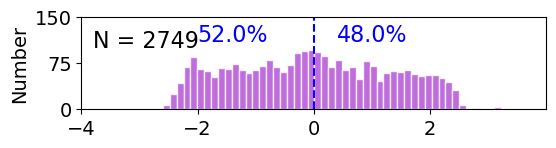

In [ ]:
import matplotlib.pyplot as plt
path_ = 'G:\ICESat-2\Discussion5_2_new\wash_bay_random_points.shp'
# path_ = 'G:\ICESat-2\Discussion5_2_new\A_wash_bay_30m_2022_new10.shp'
# path_ = 'G:\ICESat-2\Region1_map\Thames_map\A2019\A_Thames_30m_2019_new10_valid_kk.shp'
drop_rate = 0
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'Refer')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]
Z_half = q_data['Refer']

# 计算比例
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 1.2))
plt.text(-3.8, 130, f"N = {len(Z_half)}", fontsize=16, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#B048D5FF")
plt.ylabel('Number', fontsize = 14)
plt.yticks([0, 75, 150], fontsize = 14)
plt.xticks([-4, -2, 0, 2,], fontsize = 14)
plt.xlim(-4, 4)
plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0, 150)

# 在图中添加大于 0 的比例
plt.text(0.4, 110, f"{ratio:.1f}%", fontsize=16, color='blue')
plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=16, color='blue')
plt.show()


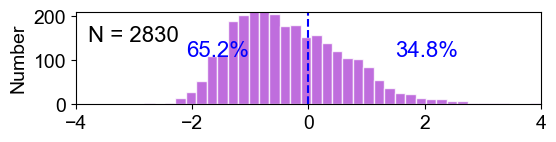

In [40]:
path_ = 'G:\ICESat-2\Discussion5_2_new\Thames_random_points.shp'
# path_ = 'G:\ICESat-2\Discussion5_2_new\A_Thames1_30m_2019_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'Refer')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]

# q_data.to_file(output_shp_path)
Z_half = q_data['Refer']
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
# plt.text(0.5, 110, f"{ratio:.1f}%", fontsize=14, color='blue')
# plt.text(-2, 110, f"{ratio2:.1f}%", fontsize=14, color='blue')

plt.figure(figsize=(6, 1.2))
plt.xticks([-4, -2, 0, 2, 4], fontsize = 14)
plt.text(-3.8, 180, f"N = 2830", fontsize=16, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#B048D5FF")  # 转换为 numpy 并设置 50 个 bins
# plt.xlabel('Height')
plt.ylabel('Number', fontsize = 14)
plt.yticks([0,  100, 200], fontsize = 14)
# plt.title('Histogram of ICESat-2 in Wash bay(2022)')
plt.xlim(-4, 4)
plt.axvline(0, color='blue', linestyle='--')
plt.ylim(0,210)
plt.text(1.5, 110, f"{ratio:.1f}%", fontsize=16, color='blue')
plt.text(-2.1, 110, f"{ratio2:.1f}%", fontsize=16, color='blue')
plt.show()

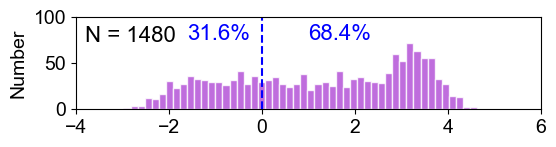

In [39]:
path_ = 'G:\ICESat-2\Discussion5_2_new\Ribble1_random_points.shp'
# path_ = 'G:\ICESat-2\Discussion5_2_new\A_Ribble1_30m_2022_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'Refer')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]

# q_data.to_file(output_shp_path)
Z_half = q_data['Refer']
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 1.2))
plt.text(-3.8, 90, f"N = {len(data)}", fontsize=16, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#B048D5FF")  # 转换为 numpy 并设置 50 个 bins
# plt.xlabel('Height')
plt.ylabel('Number', fontsize = 14)
plt.yticks([0, 50, 100], fontsize = 14)
plt.xticks([-4, -2, 0, 2, 4, 6], fontsize = 14)
# plt.title('Histogram of ICESat-2 in Wash bay(2022)')
plt.xlim(-4, 6)
plt.ylim(0,100)

plt.text(1, 75, f"{ratio:.1f}%", fontsize=16, color='blue')
plt.text(-1.6, 75, f"{ratio2:.1f}%", fontsize=16, color='blue')
plt.axvline(0, color='blue', linestyle='--')
plt.show()

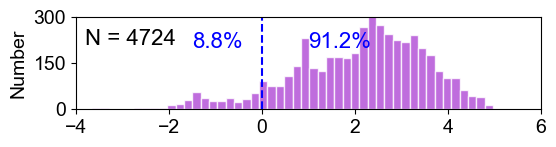

In [38]:
path_ = 'G:\ICESat-2\Discussion5_2_new\Morecambe_random_points.shp'
path_ = 'G:\ICESat-2\Discussion5_2_new\A_Morecambe_30m_2023_new10.shp'
data = gpd.read_file(path_)
data.columns
data = data.sort_values(by = 'Refer')
n_remove = int(len(data)*drop_rate/100)
q_data = data.iloc[n_remove:]

# q_data.to_file(output_shp_path)
Z_half = q_data['Refer']
ratio = (Z_half > 0).sum() / len(Z_half) * 100
ratio2 = (Z_half <= 0).sum() / len(Z_half) * 100
plt.figure(figsize=(6, 1.2))
plt.text(-3.8, 260, f"N = {len(data)}", fontsize=16, ha='left', va='top')
plt.hist(Z_half, bins=50, edgecolor='white', alpha=0.8, color="#B048D5FF")  # 转换为 numpy 并设置 50 个 bins
# plt.xlabel('Height')
plt.ylabel('Number', fontsize = 14)
plt.yticks([0, 150, 300], fontsize = 14)
plt.xticks([-4, -2, 0, 2, 4, 6], fontsize = 14)
# plt.title('Histogram of ICESat-2 in Wash bay(2022)')
plt.xlim(-4, 6)

plt.ylim(0,300)

plt.text(1,200, f"{ratio:.1f}%", fontsize=16, color='blue')
plt.text(-1.5,200, f"{ratio2:.1f}%", fontsize=16, color='blue')
plt.axvline(0, color='blue', linestyle='--')
plt.show()

In [10]:
k = gpd.read_file('G:\ICESat-2\Region1_map\Thames_map\A2019\A_Thames_30m_2019_new10_valid_kk.shp')
k.columns

Index(['Unnamed_ 0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'Ref_dem', 'Re_dem', 'geometry'],
      dtype='object')

In [7]:
path = 'G:\ICESat-2\Region2_map\Henber_map\A2019\A_Henber_30m_2019_new10.shp'
qq = gpd.read_file(path)
qq.columns

Index(['Unnamed__0', 'distance', 'mean_heigh', 'mean_lon', 'mean_lat', 'OSGM',
       'OH', 'Strip_No', 'b1_FB6', 'b2_FB6', 'b3_FB6', 'b4_FB6', 'b5_FB6',
       'b6_FB6', 'b7_FB6', 'Re_dem', 'geometry'],
      dtype='object')

In [4]:
year = 2019
validation_sample_paths_2019 = [
    # A_Thames_30m_2019_new10.shp

    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid_kk.shp',#2279
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    
]

year = 2020
validation_sample_paths_2020 = [
    # A_Thames_30m_2019_new10.shp
    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid_kk.shp',#2279
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2021
validation_sample_paths_2021 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid_kk.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp',
]


year = 2022
validation_sample_paths_2022 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676 Thames 1
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006  Henber 2
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662 wash 3
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387 holy_island 4
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid_kk.shp',#2279 Dee 5
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279 ribble 6
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510 solway 7
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424 Morecambe 8
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124 #Baglan severn 9 10
    f"G:\ICESat-2\Region5_map\Region5b_map\A2022\A_Region5b_30m_2022_new10_valid_kk.shp", #Carmathen 11
    f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'

]

year = 2023
validation_sample_paths_2023 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid_kk.shp',#2279
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2024
validation_sample_paths_2024 = [

    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #1701
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
]


# 读取并提取指定列
year = 2021
gdf_list = []
for path in validation_sample_paths_2019:
    gdf = gpd.read_file(path)
    gdf_selected = gdf[['Ref_dem', 'OH', 'Re_dem']]  # 只保留所需字段
    gdf_list.append(gdf_selected)

# 合并所有 GeoDataFrame
merged_gdf = pd.concat(gdf_list, ignore_index=True)


gdf_list = []
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]

for validation_sample_paths  in validation_sample_paths_all:
    for path in validation_sample_paths:
    
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Ref_dem', 'OH', 'Re_dem']]  # 只保留所需字段
        gdf_list.append(gdf_selected)
# 合并所有 GeoDataFrame
merged_gdf_ICESat = pd.concat(gdf_list, ignore_index=True)



DataSourceError: G:\ICESat-2\Region4_map\Ribble_map\A2020\A_Ribble_30m_2020_new10_valid_kk.shp: No such file or directory

In [13]:
year = 2019

validation_sample_paths_2019 = [
    # A_Thames_30m_2019_new10.shp

    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid_kk.shp',#2279
    f'G:\ICESat-2\Region4_map\Ribble1_map\A2019\A_Ribble1_30m_2019_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    # f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    
]


year = 2020
validation_sample_paths_2020 = [
    # A_Thames_30m_2019_new10.shp
    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    f'G:\ICESat-2\Region3_map\Region3c_map\A{year}\A_Region3c_30m_{year}_new10_kk.shp'
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2021
validation_sample_paths_2021 = [
    # A_Thames_30m_2019_new10.shp

    
    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676 1 
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006 2 
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662 3 
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387 4
    'G:\ICESat-2\Region3_map\Region3c_map\A2021\A_Region3c_30m_2021_new10_kk.shp', #5
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#Dee 6
    f'G:\ICESat-2\Region4_map\Ribble1_map\A2021\A_Ribble1_30m_2021_new10_valid.shp',# ribble  7 
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid.shp', #510 8
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424 9
    'G:\ICESat-2\Region4_map\Region4b_map\A2021\A_Region4b_30m_2021_new10_valid.shp' #10

]

year = 2022
validation_sample_paths_2022 = [
    # A_Thames_30m_2019_new10.shp
    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676 1
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006 2
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662 3 
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387 4
    f'G:\ICESat-2\Region3_map\Region3c_map\A2022\A_Region3c_30m_2022_new10_kk.shp', # 5
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279 6 
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#Dee 7 
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510 8 
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424 9
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124 10
    f"G:\ICESat-2\Region5_map\Region5b_map\A2022\A_Region5b_30m_2022_new10_valid_kk.shp", # 11
    'G:\ICESat-2\Region4_map\Region4c_map\A2022\A_Region4c_30m_2022_new10_valid.shp' #12
    # 
]

year = 2023
validation_sample_paths_2023 = [
    # A_Thames_30m_2019_new10.shp


    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid_kk.shp', #3676
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid_kk.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid_kk.shp', #1662
    f'G:\ICESat-2\Region3_map\Region3b1_map\A{year}\A_Region3b1_30m_{year}_new10_valid_kk.shp',#387
    f'G:\ICESat-2\Region4_map\Ribble_map\A{year}\A_Ribble_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Ribble1_map\A{year}\A_Ribble1_30m_{year}_new10_valid.shp',#2279
    f'G:\ICESat-2\Region4_map\Solway_map\A{year}\A_Solway_30m_{year}_new10_valid_kk.shp', #510
    f'G:\ICESat-2\Region4_map\Morecambe_map\A{year}\A_Morecambe_30m_{year}_new10_valid_kk.shp',#6424
    f'G:\ICESat-2\Region4_map\Severn_map\A{year}\A_Severn_30m_{year}_new10_valid_kk.shp',#124
    
    #f'G:\ICESat-2\Region4_map\Parrett_map\A2020\A_Parrett_30m_2020_new10.shp'   
]

year = 2024
validation_sample_paths_2024 = [

    f'G:\ICESat-2\Region1_map\Thames_map\A{year}\A_Thames_30m_{year}_new10_valid.shp', #1701
    f'G:\ICESat-2\Region2_map\Henber_map\A{year}\A_Henber_30m_{year}_new10_valid.shp', #1006
    f'G:\ICESat-2\Region2_map\wash_bay_map\A{year}\A_wash_bay_30m_{year}_new10_valid.shp', #1662

]


# 读取并提取指定列
# year = 2021
# gdf_list = []
# for path in validation_sample_paths_2021:
#     gdf = gpd.read_file(path)
#     gdf_selected = gdf[['Ref_dem', 'OH', ]]  # 只保留所需字段
#     gdf_list.append(gdf_selected)

# # 合并所有 GeoDataFrame
# merged_gdf = pd.concat(gdf_list, ignore_index=True)


gdf_list = []
validation_sample_paths_all = [validation_sample_paths_2019, validation_sample_paths_2020,
                               validation_sample_paths_2021, validation_sample_paths_2022,
                               validation_sample_paths_2023, validation_sample_paths_2024]

for validation_sample_paths  in validation_sample_paths_all:
    for path in validation_sample_paths:
    
        gdf = gpd.read_file(path)
        gdf_selected = gdf[['Ref_dem', 'OH', 'Re_dem']]  # 只保留所需字段
        gdf_list.append(gdf_selected)
# 合并所有 GeoDataFrame
merged_gdf_ICESat = pd.concat(gdf_list, ignore_index=True)



In [7]:
merged_gdf_ICESat.columns

Index(['Ref_dem', 'OH'], dtype='object')

In [14]:
len(merged_gdf_ICESat)
# z = merged_gdf_ICESat[['Ref_dem', 'OH']]
# z = merged_gdf_ICESat[['Ref_dem', 'Re_dem', 'OH']]
z = merged_gdf_ICESat[['Ref_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] != 6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z != -999]
z = z[z != 6]
z = z[z != 0]
z = z.dropna()
len(z)

46978

In [19]:
mask = ((z['Ref_dem'] - z['OH']) > 1.14)| ((z['Ref_dem'] - z['OH']) < -1.14 )
len(z[mask])*100/46978

2.3308782834518285

R² = 0.938, MAE = 0.184, MSB = 0.041, RMSE = 0.379, N = 46978


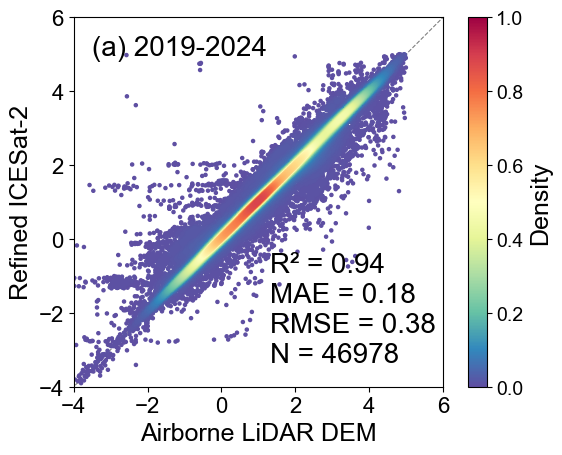

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde
from sklearn.metrics import r2_score

plt.rcParams['font.family'] = 'Arial'  # ✅ 全局字体设为 Arial

# ------------------- 你的计算部分 -------------------
year = 2024
gdf_list = []
for path in validation_sample_paths_2024:
    gdf = gpd.read_file(path)
    # gdf_selected = gdf[['Ref_dem', 'OH', 'Re_dem']]  # 只保留所需字段
    gdf_selected = gdf[['Ref_dem', 'OH']]  # 只保留所需字段
    gdf_list.append(gdf_selected)

# 合并所有 GeoDataFrame
merged_gdf = pd.concat(gdf_list, ignore_index=True)

merged_gdf = merged_gdf_ICESat
z = merged_gdf[['Ref_dem', 'OH']]
# z = merged_gdf[['Ref_dem', 'Re_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] != 6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z != -999]
z = z[z != 6]
z = z[z != 0]
z = z.dropna()

x = np.array(z['Ref_dem'])  # y_true
y = np.array(z['OH'])       # y_pred

R2 = r2_score(x, y)
MAE = np.mean(np.abs(y - x))
MSB = np.mean((y - x))
RMSE = np.sqrt(np.mean((y - x) ** 2))
num = int(len(x))

print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")

# ------------------- 绘图部分 -------------------
xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

idx = z.argsort()
x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nN = {num}"

# ax.text(
#     0.05, 0.95,
#     textstr,
#     transform=ax.transAxes,
#     fontsize=18,
#     verticalalignment='top',
#     linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
# )

ax.text(0.53, 0.05, textstr, transform=ax.transAxes, fontsize=20, verticalalignment='bottom', horizontalalignment='left')
name = '(a) 2019-2024'

# ax.text(0.55, 0.35, textstr, transform=ax.transAxes, fontsize=20,
#         verticalalignment='top')
ax.text(0.05, 0.95, name, transform=ax.transAxes, fontsize=20,
         verticalalignment = 'top')

ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
ax.set_ylabel('Refined ICESat-2', fontsize=18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

sc = ax.scatter(x_sorted, y_sorted, c=z_sorted, vmin=0, vmax=1, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)
cbar.ax.tick_params(labelsize=14) 
cbar.set_label("Density", fontsize=18)
ax.set_xlim(-4, 5)
ax.set_ylim(-4, 5)

tick_interval = 2
ticks = np.arange(-4, 5 + tick_interval, tick_interval)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax.set_aspect('equal')
ax.tick_params(axis='both', labelsize=16)

plt.show()
plt.close()


146534

R² = 0.876, MAE = 0.360, MSB = 0.050, RMSE = 0.542, N = 45395


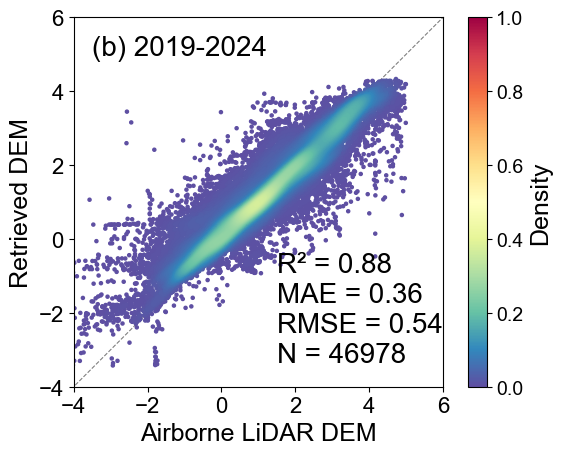

In [19]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde
from sklearn.metrics import r2_score

plt.rcParams['font.family'] = 'Arial'  # ✅ 全局字体设为 Arial

# ------------------- 你的计算部分 -------------------
year = 2019
gdf_list = []
for path in validation_sample_paths_2019:
    gdf = gpd.read_file(path)
    gdf_selected = gdf[['Ref_dem', 'OH', 'Re_dem']]  # 只保留所需字段
    gdf_list.append(gdf_selected)

# 合并所有 GeoDataFrame
merged_gdf = pd.concat(gdf_list, ignore_index=True)

merged_gdf = merged_gdf_ICESat
# z = merged_gdf[['Ref_dem', 'OH']]
# z = merged_gdf[['Ref_dem', 'Re_dem', 'OH']]
# mask = (z['OH'] != 0) | (z['Ref_dem'] != 6) | (z['Ref_dem'] != -999)
# z = z[mask]
# z = z[z != -999]
# z = z[z != 6]
# z = z[z != 0]
# z = z.dropna()

z = merged_gdf[['Ref_dem', 'OH', 'Re_dem']]
# z = merged_gdf[['Ref_dem', 'Re_dem', 'OH']]
mask = (z['OH'] != 0) | (z['Ref_dem'] != 6) | (z['Ref_dem'] != -999)
z = z[mask]
z = z[z != -999]
z = z[z != 6]
z = z[z != 0]
z = z.dropna()

x = np.array(z['Ref_dem'])  # y_true
y = np.array(z['OH'])       # y_pred



x = np.array(z['Ref_dem'])  # y_true
y = np.array(z['Re_dem'])       # y_pred

R2 = r2_score(x, y)
MAE = np.mean(np.abs(y - x))
MSB = np.mean((y - x))
RMSE = np.sqrt(np.mean((y - x) ** 2))
num = int(len(x))

print(f"R² = {R2:.3f}, MAE = {MAE:.3f}, MSB = {MSB:.3f}, RMSE = {RMSE:.3f}, N = {num}")

# ------------------- 绘图部分 -------------------
xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

idx = z.argsort()
x_sorted, y_sorted, z_sorted = x[idx], y[idx], z[idx]

fig, ax = plt.subplots()
textstr = f"R² = {R2:.2f}\nMAE = {MAE:.2f}\nRMSE = {RMSE:.2f} \nN = 46978"

# ax.text(
#     0.05, 0.95,
#     textstr,
#     transform=ax.transAxes,
#     fontsize=18,
#     verticalalignment='top',
#     linespacing=1.2   # 默认是 1.0，调大就会加宽行间距
# )

ax.text(0.55, 0.05, textstr, transform=ax.transAxes, fontsize=20, verticalalignment='bottom', horizontalalignment='left')
name = '(b) 2019-2024'

# ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=18,
#         verticalalignment='top')
ax.text(0.05, 0.95, name, transform=ax.transAxes, fontsize=20,
         verticalalignment = 'top')

ax.set_xlabel('Airborne LiDAR DEM', fontsize=18)
ax.set_ylabel('Retrieved DEM', fontsize=18)
ax.plot([-6, 6], [-6, 6], color='gray', linestyle='--', linewidth=0.8, zorder=1)

sc = ax.scatter(x_sorted, y_sorted, c=z_sorted, vmin=0, vmax=1, s=5, cmap='Spectral_r', zorder=2)
cbar = plt.colorbar(sc)
cbar.ax.tick_params(labelsize=14) 
cbar.set_label("Density", fontsize=18)
ax.set_xlim(-4, 5)
ax.set_ylim(-4, 5)

tick_interval = 2
ticks = np.arange(-4, 5 + tick_interval, tick_interval)
ax.set_xticks(ticks)
ax.set_yticks(ticks)

ax.set_aspect('equal')
ax.tick_params(axis='both', labelsize=16)

plt.show()
plt.close()
